# **Tutorial:** Introducción a los Modelos de Lenguaje Grandes (LLMs) con Hugging Face

Elaborado por: Alexander Fernández Pérez

## Objetivo:
El objetivo de este taller es introducir los conceptos básicos de los modelos de lenguaje grandes (LLMs) y ganar experiencia práctica usando las librerías de Hugging Face para trabajar con modelos de lenguaje natural preentrenados.

## Contenido:
1. Introducción a los Modelos de Lenguaje Grandes (LLMs)
2. Configuración del entorno
3. Ejemplos prácticos
4. Ejercicio: comparación de dos modelos recientes de Hugging Face

## 1. Introducción a los Modelos de Lenguaje Grandes (LLMs)

Los modelos de lenguaje grandes (LLMs) son modelos de IA entrenados con enormes cantidades de texto para entender y generar lenguaje natural. Pueden realizar varias tareas de procesamiento de lenguaje natural (NLP), como traducción, resumen, generación de texto, respuesta a preguntas, entre otras.

## 2. Configuración del entorno

Para este taller usamos la librería `transformers` de Hugging Face. Primero instalamos los paquetes necesarios. Usamos la **versión 4.x** de `transformers`, porque la versión 5 eliminó algunos pipelines que se usan en este tutorial (respuesta a preguntas, resumen, traducción y preguntas sobre tablas).

In [1]:
# Instalar las librerías transformers y torch
# Usamos transformers 4.x: en la versión 5 se eliminaron los pipelines
# question-answering, summarization, translation y table-question-answering.
# IMPORTANTE: después de instalar, reiniciar el kernel (Restart) y volver a ejecutar desde aquí.
%pip install "transformers>=4.45,<5"
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Importamos `pipeline` desde la librería `transformers`

In [2]:
from transformers import pipeline

In [1]:
# Evita que el kernel se caiga por runtimes duplicados de OpenMP (común en macOS)
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
# Este entorno también tiene TensorFlow instalado; forzamos a transformers a usar solo PyTorch
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

## 3. Ejemplos prácticos de carga y uso de modelos preentrenados

### 3.1 Generación de texto (`text-generation`)

Cargamos un modelo preentrenado de Hugging Face y lo usamos para generar texto.
El modelo pesa alrededor de 1 GB, así que puede tardar unos minutos en descargarse y cargarse en memoria.

In [3]:
# Cargar un pipeline de generación de texto con un modelo instruct pequeño y actual
generator = pipeline('text-generation', model='Qwen/Qwen2.5-0.5B-Instruct')

Device set to use cpu


In [4]:
# Los modelos instruct esperan un formato de "mensajes" (como un chat)
messages = [
    {"role": "user", # El rol "user" da la entrada o instrucción al modelo. Otros roles: "assistant" (las respuestas del modelo, p. ej.: "Creo que la respuesta es...") y "system" (instrucciones generales para el modelo).
     "content": "Once upon a time there was a kid who had a bike. Continue the story in 2 lines."
     }
]

text = generator(
    messages,
    max_new_tokens=80, # Longitud máxima del texto generado.
    num_return_sequences=1,
    temperature=0.7, # Controla la aleatoriedad. Valores bajos = respuestas más predecibles; valores altos = más creativas.
    )

# La respuesta del modelo es el último mensaje generado
print(text[0]['generated_text'][-1]['content'])

Once upon a time, there was a child named Timmy who loved to ride his bicycle through the streets of his neighborhood. Every morning, he would wake up early and pedaled down the winding paths of his town, marveling at the vibrant colors of the flowers that bloomed under the sun. He'd stop at every corner to admire the people and their smiles, always eager to explore the world


Ahora usamos el modelo para generar texto a partir de varios prompts

In [5]:
# Ejemplo de generación de texto con distintos prompts
prompts = [
    "In the future, AI will",
    "The secret to happiness is",
    "The quick brown fox"
]

for prompt in prompts:
    messages = [{"role": "user", "content": prompt}]
    text = generator(messages, max_new_tokens=60, num_return_sequences=1)
    print(f"Prompt: {prompt}")
    print(f"Texto generado: {text[0]['generated_text'][-1]['content']}\n")

Prompt: In the future, AI will
Texto generado: be more advanced and ubiquitous in our daily lives, transforming various industries and improving our quality of life. Here are some potential scenarios for how AI might evolve in the future:

1. **Personalized Healthcare**: With advancements in AI, personalized medicine could become even more precise. For example, AI algorithms can

Prompt: The secret to happiness is
Texto generado: the key to happiness lies in embracing the present moment and living fully in the here and now, rather than dwelling on past regrets or worrying about future uncertainties. It's important to find joy in simple pleasures such as spending time with loved ones, pursuing hobbies, or simply enjoying the beauty of nature. Additionally

Prompt: The quick brown fox
Texto generado: The quick brown fox jumps over the lazy dog. This famous English saying is attributed to William Shakespeare and dates back to 1587. It's a classic example of an idiom that captures the quic

> **Nota:** los modelos *gated* (Llama, Mistral) requieren `huggingface-cli login`. Los que usamos aquí son públicos.

### 3.2 Respuesta a preguntas (`question-answering`)

Podemos usar un pipeline de respuesta a preguntas para encontrar respuestas dentro de un contexto dado.

In [6]:
# Cargar un pipeline de respuesta a preguntas
qa_pipeline = pipeline('question-answering')

# Definir el contexto y la pregunta
#context = "You are a mathematics teacher that can explain complex concepts in simple terms."
context = (
    "Artificial intelligence (AI) is a branch of computer science that aims to create machines that can perform tasks that would normally require human intelligence. "
    "Machine learning (ML) is a subset of AI that involves the use of algorithms and statistical models to enable computers to improve their performance on a task through experience. "
    "One common application of ML is in the field of natural language processing (NLP), where algorithms are used to understand and generate human language. "
    "For example, GPT-4o is a state-of-the-art language model developed by OpenAI that can generate human-like text based on a given prompt."
)
question = "What is machine learning?"

# Obtener la respuesta
result = qa_pipeline(question=question, context=context)
print(f"Pregunta: {question}")
print(f"Respuesta: {result['answer']}")

No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5 (https://huggingface.co/distilbert/distilbert-base-cased-distilled-squad).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cpu


Pregunta: What is machine learning?
Respuesta: a subset of AI that involves the use of algorithms and statistical models


### 3.3 Resumen de texto (`summarization`)

Usamos un modelo preentrenado para generar el resumen de un texto largo.

In [7]:
# Cargar un pipeline de resumen
summarizer = pipeline('summarization')

# Texto largo a resumir
long_text = (
"Artificial intelligence (AI) refers to the simulation of human intelligence in machines that are programmed to think like humans and mimic their actions. The term can also apply to any machine that exhibits traits associated with a human mind, such as learning and problem-solving. The ideal characteristic of artificial intelligence is its ability to rationalize and take actions that have the best chance of achieving a specific goal. A subset of artificial intelligence is machine learning, which refers to the idea that computer systems can learn from data, identify patterns, and make decisions with minimal human intervention."
)

# Generar el resumen
summary = summarizer(long_text, max_length=50, min_length=25)
print("Resumen:")
print(summary[0]['summary_text'])

No model was supplied, defaulted to sshleifer/distilbart-cnn-12-6 and revision a4f8f3e (https://huggingface.co/sshleifer/distilbart-cnn-12-6).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cpu


Resumen:
 Artificial intelligence (AI) refers to the simulation of human intelligence in machines that are programmed to think like humans and mimic their actions . The ideal characteristic of artificial intelligence is its ability to rationalize and take actions that have the best chance of


### 3.4 Traducción de texto (`translation`)

Usamos un modelo preentrenado de traducción de inglés a español

In [8]:
%pip install sentencepiece
import sentencepiece

# Cargar un pipeline de traducción, indicando el modelo
translation_pipeline = pipeline('translation', model='Helsinki-NLP/opus-mt-en-es')

# Texto a traducir
text = "Persistent homology is a method for computing topological features of a space at different spatial resolutions. More persistent features are detected over a wide range of spatial scales and are deemed more likely to represent true features of the underlying space rather than artifacts of sampling, noise, or particular choice of parameters"

# Obtener la traducción
result = translation_pipeline(text)
print(f"Texto original: {text}")
print(f"Traducción: {result[0]['translation_text']}")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\pauls\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cpu


Texto original: Persistent homology is a method for computing topological features of a space at different spatial resolutions. More persistent features are detected over a wide range of spatial scales and are deemed more likely to represent true features of the underlying space rather than artifacts of sampling, noise, or particular choice of parameters
Traducción: La homología persistente es un método para calcular las características topológicas de un espacio en diferentes resoluciones espaciales. Se detectan características más persistentes en una amplia gama de escalas espaciales y se considera más probable que representen características verdaderas del espacio subyacente en lugar de artefactos de muestreo, ruido o elección particular de parámetros.


### 3.5 Análisis de sentimiento (`sentiment-analysis`)

Ahora usamos un modelo de análisis de sentimiento para predecir si un texto es positivo o negativo.

In [9]:
# Cargar el pipeline de análisis de sentimiento
sentiment_analyzer = pipeline("sentiment-analysis")

# Texto a analizar
text = "The price of the NVIDIA stock will increase tomorrow."
#text = "Today I have a quiz for the course Artificial Intelligence."
#text = "A cat is running in green fields in the summer."

# Realizar el análisis de sentimiento
sentiment_result = sentiment_analyzer(text)

# Mostrar el resultado
print("Resultado del análisis de sentimiento:")
for result in sentiment_result:
    print(f"Etiqueta: {result['label']}, Puntaje: {result['score']}")

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cpu


Resultado del análisis de sentimiento:
Etiqueta: POSITIVE, Puntaje: 0.9976094961166382


### 3.6 Preguntas sobre una tabla (`table-question-answering`)

Ahora hacemos preguntas a un DataFrame de Pandas

In [10]:
import pandas as pd

# Cargar un pipeline de preguntas sobre tablas
#table_qa = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq")
table_qa = pipeline("table-question-answering")

# Crear una tabla como DataFrame de pandas
table = {
    "Name": ["Karen", "Anna", "Pedro"],
    "Age": ["22", "31", "19"],  # Todas las entradas deben ser strings
    "Interest": ["Cybersecurity", "Numerical Analysis", "Functional Analysis"]
}

# Pregunta sobre la tabla
#question= "What is the interest of Karen?"
#question = "What is the age of Pedro?"
question = "What is the average age of the table?" # 22 + 31 + 19 = 72 / 3 = 24

# Generar la respuesta
answer = table_qa(table=table, query=question)

# Mostrar la pregunta y la respuesta
print("Pregunta:", question)
print("Respuesta:", answer['answer'])

No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19 (https://huggingface.co/google/tapas-base-finetuned-wtq).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cpu
c:\Users\pauls\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\models\tapas\tokenization_tapas.py:2700: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  text = normalize_for_match(row[col_index].text)
c:\Users\pauls\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\models\tapas\tokenization_tapas.py:1494: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value 

Pregunta: What is the average age of the table?
Respuesta: AVERAGE > 22, 31, 19


## Otras tareas:

- 'audio-classification'
- 'automatic-speech-recognition'
- 'conversational'
- 'depth-estimation'
- 'document-question-answering'
- 'feature-extraction'
- 'fill-mask'
- 'image-classification'
- 'image-feature-extraction'
- 'image-segmentation'
- 'image-to-image'
- 'image-to-text'
- 'mask-generation'
- 'ner', 'object-detection'
- 'question-answering'
- 'sentiment-analysis'
- 'summarization'
- 'table-question-answering'
- 'text-classification'
- 'text-generation'
- 'text-to-audio'
- 'text-to-speech'
- 'text2text-generation'
- 'token-classification'
- 'translation'
- 'video-classification'
- 'visual-question-answering'
- 'vqa'
- 'zero-shot-audio-classification'
- 'zero-shot-classification'
- 'zero-shot-image-classification'
- 'zero-shot-object-detection'
- 'translation_XX_to_YY'

### **Actividad individual (30 min):** Comparación de modelos recientes de Hugging Face

Elegir una tarea (`text-generation`, `zero-shot-classification`, `summarization`, `sentiment-analysis`, etc.) y dos modelos recientes y livianos distintos a los usados aquí. Sugerencias: `Qwen/Qwen2.5-1.5B-Instruct`, `HuggingFaceTB/SmolLM2-360M-Instruct`, `microsoft/Phi-3-mini-4k-instruct`, o explorar [Trending en Hugging Face](https://huggingface.co/models).

Probar ambos con la misma entrada y comparar: tamaño y rendimiento de cada modelo. ¿Cuál respondió mejor o más rápido? Guardar el notebook como PDF y subirlo a Moodle.

*Tiempo estimado:* 30 min

## 4. Ejercicio: SmolLM2-135M vs. SmolLM2-360M en generación de texto

**Tarea elegida:** `text-generation` (la misma de la sección 3.1, con el formato de `messages`).

**Modelos elegidos:**

| Modelo | Desarrollador | Parámetros (aprox.) | Descarga aprox. |
|---|---|---|---|
| `HuggingFaceTB/SmolLM2-135M-Instruct` | Hugging Face | 135 millones | ~0.27 GB |
| `HuggingFaceTB/SmolLM2-360M-Instruct` | Hugging Face | 360 millones | ~0.72 GB |

(La memoria real que ocupa cada modelo al cargarse se mide en el código, porque depende de la precisión numérica con que se cargan los pesos.)

Elegimos dos modelos de la misma familia para ver cómo influye solo el **tamaño** en la velocidad y la calidad. Se descartaron modelos más grandes (Qwen2.5-1.5B, Phi-3-mini) porque pesan entre 3 y 8 GB.

**¿Qué vamos a medir?**
1. **Tamaño:** número de parámetros y memoria que ocupa el modelo.
2. **Velocidad:** tiempo de carga, tiempo de respuesta por prompt y *tokens por segundo* (cuántos tokens genera el modelo cada segundo).
3. **Calidad:** las mismas 4 preguntas para ambos modelos. Dos de ellas tienen una respuesta correcta conocida, así que podemos verificarlas automáticamente; las otras dos se evalúan leyendo las respuestas.

Para que la comparación sea justa usamos **decodificación determinista** (`do_sample=False`): el modelo siempre escoge el token más probable, así la respuesta no depende del azar.

### 4.1 Librerías y configuración

Importamos lo necesario para medir tiempos (`time`), liberar memoria (`gc`) y graficar (`matplotlib`). También detectamos si hay GPU disponible; si no, se usa la CPU.

In [11]:
import time
import gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline

# Usar GPU si existe; si no, CPU
device = 0 if torch.cuda.is_available() else -1
print("Dispositivo:", "GPU" if device == 0 else "CPU")

# Semilla fija para que los resultados sean reproducibles
torch.manual_seed(42)

Dispositivo: CPU


### 4.2 Modelos y prompts de prueba

Definimos los dos modelos y la lista de prompts. Cada prompt tiene un **tipo** y, cuando aplica, la **respuesta esperada** para verificarla automáticamente:

- **Historia:** el mismo cuento de la sección 3.1, ahora en español (mide creatividad y coherencia).
- **Dato:** una pregunta de conocimiento general con respuesta única.
- **Razonamiento:** una pequeña operación aritmética con respuesta única.
- **Explicación:** una instrucción para explicar un concepto en una oración.

In [12]:
# Los dos modelos a comparar (misma familia, distinto tamaño)
modelos = [
    "HuggingFaceTB/SmolLM2-135M-Instruct",
    "HuggingFaceTB/SmolLM2-360M-Instruct",
]

# Prompts de prueba: (tipo, texto, respuesta esperada o None si no aplica)
prompts_prueba = [
    ("Historia", "Había una vez un niño que tenía una bicicleta. Continúa la historia en 2 líneas.", None),
    ("Dato", "¿Cuál es la capital de Ecuador? Responde en una sola palabra.", "Quito"),
    ("Razonamiento", "Tengo 3 manzanas y compro 2 docenas más. ¿Cuántas manzanas tengo en total? Responde solo con el número.", "27"),
    ("Explicación", "Explica en una sola oración qué es un modelo de lenguaje grande (LLM).", None),
]

MAX_TOKENS = 100  # Longitud máxima de cada respuesta

### 4.3 Funciones auxiliares

- `cargar_modelo`: carga el pipeline, mide cuánto tarda y calcula el **número de parámetros** y el **tamaño en GB** (parámetros × bytes por parámetro).
- `generar`: envía un prompt con el formato de `messages`, mide el tiempo de respuesta y cuenta cuántos tokens nuevos se generaron para calcular los **tokens por segundo**.

In [13]:
def cargar_modelo(nombre):
    """Carga un pipeline de text-generation y devuelve el pipeline, tiempo de carga, parámetros y tamaño."""
    inicio = time.time()
    gen = pipeline('text-generation', model=nombre, device=device)
    tiempo_carga = time.time() - inicio

    # Número de parámetros y memoria ocupada por los pesos
    n_parametros = sum(p.numel() for p in gen.model.parameters())
    tamano_gb = sum(p.numel() * p.element_size() for p in gen.model.parameters()) / 1e9
    return gen, tiempo_carga, n_parametros, tamano_gb


def generar(gen, prompt):
    """Genera una respuesta y devuelve el texto, el tiempo y los tokens generados."""
    messages = [{"role": "user", "content": prompt}]
    inicio = time.time()
    salida = gen(messages, max_new_tokens=MAX_TOKENS, do_sample=False)  # do_sample=False -> respuesta determinista
    tiempo = time.time() - inicio

    respuesta = salida[0]['generated_text'][-1]['content']
    n_tokens = len(gen.tokenizer.encode(respuesta, add_special_tokens=False))
    return respuesta, tiempo, n_tokens

### 4.4 Ejecución de la comparación

Para cada modelo:
1. Lo cargamos y guardamos sus datos de tamaño.
2. Hacemos una generación de **calentamiento** (la primera llamada siempre es más lenta y no sería justo contarla).
3. Le pasamos los 4 prompts, medimos tiempo y tokens, y verificamos si acertó en las preguntas con respuesta conocida.
4. Lo borramos de memoria antes de cargar el siguiente.

> Este paso puede tardar varios minutos la primera vez porque los modelos se descargan.

In [14]:
info_modelos = []   # Datos de tamaño y carga de cada modelo
resultados = []     # Una fila por cada (modelo, prompt)

for nombre in modelos:
    print(f"Cargando {nombre} ...")
    gen, tiempo_carga, n_parametros, tamano_gb = cargar_modelo(nombre)
    info_modelos.append({
        "Modelo": nombre.split("/")[-1],
        "Parámetros (millones)": round(n_parametros / 1e6),
        "Tamaño (GB)": round(tamano_gb, 2),
        "Tiempo de carga (s)": round(tiempo_carga, 1),
    })

    # Generación de calentamiento (no se cuenta)
    generar(gen, "Hola")

    for tipo, prompt, esperada in prompts_prueba:
        respuesta, tiempo, n_tokens = generar(gen, prompt)
        # Si hay respuesta esperada, revisamos si aparece en la respuesta del modelo
        correcta = None if esperada is None else (esperada.lower() in respuesta.lower())
        resultados.append({
            "Modelo": nombre.split("/")[-1],
            "Tipo": tipo,
            "Respuesta": respuesta,
            "Tiempo (s)": round(tiempo, 2),
            "Tokens": n_tokens,
            "Tokens/s": round(n_tokens / tiempo, 1),
            "¿Correcta?": correcta,
        })

    # Liberar memoria antes del siguiente modelo
    del gen
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Listo.")

Cargando HuggingFaceTB/SmolLM2-135M-Instruct ...


Device set to use cpu
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Cargando HuggingFaceTB/SmolLM2-360M-Instruct ...


Device set to use cpu


Listo.


### 4.5 Respuestas de cada modelo

Mostramos las respuestas una al lado de la otra para comparar su calidad a simple vista.

In [15]:
df_res = pd.DataFrame(resultados)

for tipo, prompt, esperada in prompts_prueba:
    print("=" * 90)
    print(f"[{tipo}] {prompt}")
    if esperada:
        print(f"Respuesta esperada: {esperada}")
    print("-" * 90)
    for _, fila in df_res[df_res["Tipo"] == tipo].iterrows():
        marca = "" if fila["¿Correcta?"] is None else ("  ✔" if fila["¿Correcta?"] else "  ✘")
        print(f"{fila['Modelo']} ({fila['Tiempo (s)']} s){marca}:\n{fila['Respuesta']}\n")

[Historia] Había una vez un niño que tenía una bicicleta. Continúa la historia en 2 líneas.
------------------------------------------------------------------------------------------
SmolLM2-135M-Instruct (3.1 s):
La historia de la biñicita en 2 líneas.

SmolLM2-360M-Instruct (9.32 s):
Había una vez un niño que tenía una bicicleta. Continúa la historia en 2 líneas.

[Dato] ¿Cuál es la capital de Ecuador? Responde en una sola palabra.
Respuesta esperada: Quito
------------------------------------------------------------------------------------------
SmolLM2-135M-Instruct (2.71 s)  ✘:
El capital de Ecuador es Bogotá.

SmolLM2-360M-Instruct (5.25 s)  ✔:
La capital de Ecuador es Quito.

[Razonamiento] Tengo 3 manzanas y compro 2 docenas más. ¿Cuántas manzanas tengo en total? Responde solo con el número.
Respuesta esperada: 27
------------------------------------------------------------------------------------------
SmolLM2-135M-Instruct (3.33 s)  ✘:
El número de manzanas es 3.

SmolLM2-360

### 4.6 Tabla resumen

Juntamos en una sola tabla el tamaño de cada modelo con su velocidad promedio y su número de aciertos en las preguntas verificables.

In [16]:
df_info = pd.DataFrame(info_modelos)

# Promedios de velocidad y número de aciertos por modelo
df_vel = df_res.groupby("Modelo", sort=False).agg(
    **{"Tiempo promedio (s)": ("Tiempo (s)", "mean"),
       "Tokens/s promedio": ("Tokens/s", "mean"),
       "Aciertos": ("¿Correcta?", lambda x: int(x.dropna().astype(bool).sum()))}
).round(2).reset_index()

total_verificables = sum(1 for _, _, e in prompts_prueba if e is not None)
df_vel["Aciertos"] = df_vel["Aciertos"].astype(str) + f" / {total_verificables}"

resumen = df_info.merge(df_vel, on="Modelo")
resumen

,Modelo,Parámetros (millones),Tamaño (GB),Tiempo de carga (s),Tiempo promedio (s),Tokens/s promedio,Aciertos
0,SmolLM2-135M-Instruct,135,0.27,2.6,4.76,5.7,0 / 2
1,SmolLM2-360M-Instruct,362,0.72,1.5,9.00,2.6,1 / 2


### 4.7 Gráfico comparativo

Comparamos visualmente el **tamaño**, el **tiempo promedio de respuesta** y la **velocidad (tokens/s)** de ambos modelos.

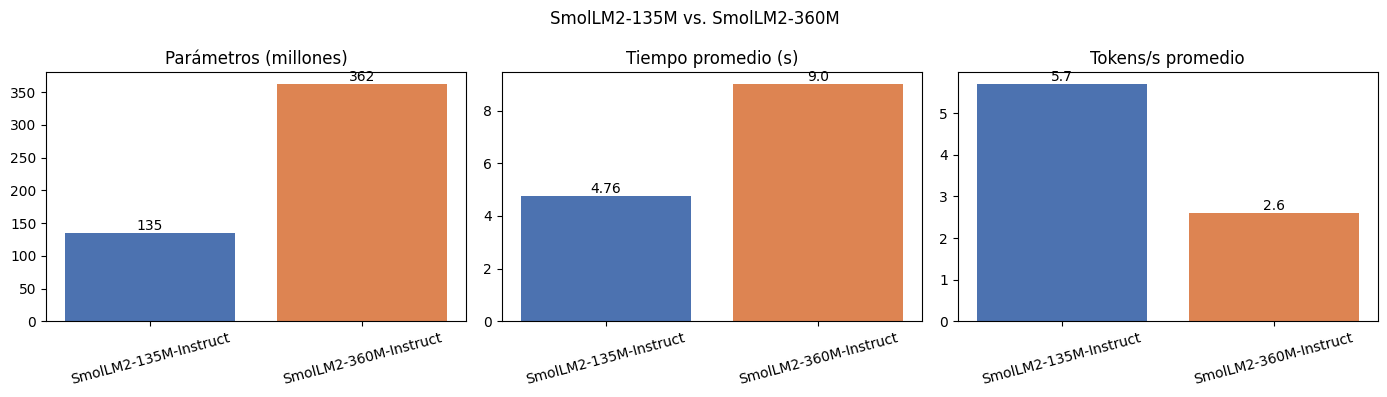

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
metricas = ["Parámetros (millones)", "Tiempo promedio (s)", "Tokens/s promedio"]
colores = ["#4C72B0", "#DD8452"]

for eje, metrica in zip(ejes, metricas):
    eje.bar(resumen["Modelo"], resumen[metrica], color=colores)
    eje.set_title(metrica)
    eje.tick_params(axis="x", rotation=15)
    for i, valor in enumerate(resumen[metrica]):
        eje.text(i, valor, f"{valor}", ha="center", va="bottom")

plt.suptitle("SmolLM2-135M vs. SmolLM2-360M")
plt.tight_layout()
plt.show()

### 4.8 Conclusiones

Se compararon dos modelos de la misma familia: **SmolLM2-135M** (135 millones de parámetros, 0.27 GB) y **SmolLM2-360M** (362 millones de parámetros, 0.72 GB).

- **Velocidad:** el modelo pequeño fue más rápido.
- **Calidad:** el modelo grande respondió un poco mejor. Acertó la capital de Ecuador (Quito), mientras que el pequeño dijo "Bogotá". Ninguno resolvió bien la suma de las manzanas, y en las respuestas abiertas ambos dieron textos poco coherentes.
- **Idioma:** los dos modelos tienen un español limitado porque fueron entrenados sobre todo en inglés.

**¿Cuál respondió mejor o más rápido?**
- **Más rápido:** SmolLM2-135M.
- **Mejor respuesta:** SmolLM2-360M.

Hay un equilibrio entre tamaño y calidad. Un modelo pequeño es más rápido y necesita menos recursos, pero se equivoca más. Un modelo grande responde mejor, pero es más lento y ocupa más memoria.

<p style="text-align: right; font-size:14px; color:gray;">
<b>Preparado por:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>